In [1]:
!pip install pyreadstat

# **Occupational hardiness and work engagement**
## A secondary analysis of survey data from Italian workers

### Research question

How are commitment, control, and challenge associated with work engagement after accounting for age and gender?

### Project overview

This project uses Python to analyse an existing dataset of 1,152 observations from Italian workers. The main regression includes 841 participants with complete data on all variables required for the model.

The outcome is work engagement, calculated as the mean of vigor, dedication, and absorption. The main predictors are the three dimensions of occupational hardiness: commitment, control, and challenge. Age and gender are included as covariates.

The analysis follows five steps:

1. Inspect the dataset, check variable ranges, and identify missing values.
2. Describe the analysis sample and examine correlations.
3. Compare a regression model including age and gender with a model that also includes the three hardiness dimensions.
4. Examine model diagnostics and use HC3 robust standard errors for confidence intervals and significance tests.
5. Explore how the findings change when using an alternative engagement measure and a larger sample.

### Scope and limitations

This project is a secondary analysis of cross-sectional, self-report data. It examines associations and cannot establish whether hardiness causes changes in engagement.

Missing absorption scores reduce the main analysis sample. A sensitivity analysis compares different outcome definitions and samples to assess how these choices affect the results. This comparison does not recover the missing values or eliminate possible selection bias.

The aim is to interpret the observed relationships carefully, rather than to build a prediction tool or evaluate an intervention.

## 1. Theoretical framework and hypotheses

### Occupational hardiness

Hardiness describes an orientation towards involvement, influence,
and openness to change (Kobasa, 1979). In the work context,
it includes three dimensions:

- **Commitment:** feeling involved in work and finding it meaningful.
- **Control:** believing that one can influence events and outcomes at work.
- **Challenge:** viewing change and difficulties as opportunities
  for learning rather than only as threats.

### Work engagement

Work engagement is a positive psychological state related to work
(Schaufeli et al., 2002). It includes:

- **Vigor:** energy and persistence at work.
- **Dedication:** enthusiasm, pride, and a sense of significance.
- **Absorption:** being deeply concentrated in work.

### Why examine their relationship?

The Job Demands–Resources model provides a framework for understanding
how resources relate to motivation and engagement
(Bakker & Demerouti, 2007).

Within this perspective, occupational hardiness can be considered
a personal resource that may help workers approach demanding
situations. This motivates the expectation that higher hardiness
scores will be associated with higher engagement.

### Hypotheses

The regression examines the following expectations, accounting
for age, gender, and the other two hardiness dimensions:

- **H1:** Higher commitment is associated with higher work engagement.
- **H2:** Higher control is associated with higher work engagement.
- **H3:** Higher challenge is associated with higher work engagement.

These are hypotheses about associations, not causal effects.

### Measures used in this project

The study accompanying the dataset (Panari et al., 2026) describes
two instruments:

- **Occupational Hardiness Scale (OHS):** 15 items, with five items
  for each hardiness dimension. Responses range from 1 to 4.
- **Utrecht Work Engagement Scale (UWES-9):** nine items, with three
  items for each engagement dimension. Responses range from 0 to 6.

The available file contains subscale scores rather than individual
item responses. This project uses the supplied commitment, control,
and challenge scores as predictors.

The main engagement score is the equally weighted mean of vigor,
dedication, and absorption. It is calculated only for participants
with all three subscale scores available and remains on a 0–6 scale.

Item-level scoring and reliability cannot be independently checked
using this file.

### Interpretation note

Commitment and dedication both involve a sense of involvement
and meaning at work. Their conceptual overlap may partly explain
the association between commitment and engagement. This should
be considered when interpreting the findings.

### Dataset study

Panari, C., Mazzetti, G., Lo Piccolo, E., Guglielmi, D., & Simbula, S.
(2026). A contribution to the Italian validation of the occupational
hardiness scale and its role in work engagement and emotional
exhaustion. *Scientific Reports, 16*, 924.

https://doi.org/10.1038/s41598-025-29016-z

### Data source and analytical approach

The dataset was obtained from the Open Science Framework (OSF)
repository accompanying Panari et al. (2026).

- [OSF repository](https://osf.io/cegvt/?view_only=1cdd5ff1d22f44f28a10e8bee7ed3acc)
- [Original article](https://doi.org/10.1038/s41598-025-29016-z)
- Data file: `Occupational_hardiness_ITA.sav`

The loaded dataset contains 1,152 observations. The main regression
uses 841 participants with complete data on age, gender, the three
hardiness dimensions, and the three engagement subscales.
The sample-flow table below documents these exclusions.

This project is a secondary analysis: I did not collect the data.
My contribution is to prepare and explore the available data,
fit and interpret multiple regression models, examine model
diagnostics, and assess the sensitivity of the findings to
the outcome definition and sample selection.

The main analysis uses the mean of vigor, dedication, and absorption
as the engagement score. A sensitivity analysis uses the mean of
vigor and dedication, first in the same 841 participants and then
in a larger sample of 1,129 participants.

The two-subscale score is an alternative measure and is not treated
as equivalent to the full three-subscale engagement score.
No missing values are imputed.

## 2. **Data loading and cleaning**

In [2]:
from pathlib import Path
import platform
from google.colab import drive

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyreadstat
import scipy
import statsmodels

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.nonparametric.smoothers_lowess import lowess

# Connect Google Drive
drive.mount("/content/drive")

# Display settings
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
pd.set_option("display.width", 140)

# Persistent project folder on Google Drive
PROJECT_DIR = Path("/content/drive/MyDrive/Hardiness_Project")
DATA_PATH = PROJECT_DIR / "Occupational_hardiness_ITA.sav"

# Check that the dataset is available
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}. Check the folder and filename."
    )

# Save exported figures on Google Drive too
FIG_DIR = PROJECT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

print("Dataset found:", DATA_PATH.name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset found: Occupational_hardiness_ITA.sav


In [3]:
# Load the dataset and its metadata
raw, meta = pyreadstat.read_sav(DATA_PATH)

print(f"Dataset: {raw.shape[0]} observations, {raw.shape[1]} columns")

# Remove columns that contain no observed values
empty_cols = raw.columns[raw.isna().all()].tolist()
raw = raw.drop(columns=empty_cols)

print(f"Removed entirely empty columns: {empty_cols}")

# Summarise missing values for each remaining variable
missing = pd.DataFrame({
    "Missing N": raw.isna().sum(),
    "Missing %": raw.isna().mean() * 100
})

display(missing.round(2))

Dataset: 1152 observations, 16 columns
Removed entirely empty columns: ['VAR00001', 'VAR00002', 'VAR00003', 'VAR00004']


,Missing N,Missing %
GENDER,0,0.000
AGE,13,1.130
EDUCATION,746,64.760
JOB_TENURE,255,22.140
CONTRACT,471,40.890
COMMITMENT,0,0.000
CONTROL,0,0.000
CHALLENGE,0,0.000
EXHAUSTION,10,0.870
VIGOR,10,0.870


### Missing data and choice of covariates

The three hardiness dimensions have no missing values.
Among the engagement subscales, absorption has the highest
proportion of missing values (25.1%), compared with vigor
(0.9%) and dedication (0.2%).

Because the main engagement score requires all three subscales,
missing absorption scores are the main reason for the reduction
in the analysis sample.

Age and gender are included as basic demographic covariates.
Education and contract type are not included in this model:
they have substantial missingness (64.8% and 40.9%, respectively),
and requiring complete data on them would further restrict
the sample.

This is a limited adjustment strategy. It does not account
for all potentially relevant personal or workplace characteristics.

The sample-flow table below shows how many participants remain
after each completeness requirement. Later, a sensitivity analysis
examines how the results change with an alternative engagement
measure and a larger sample.

In [4]:
# Inspect the observed range of the variables used in the analysis
check_vars = [
    "AGE",
    "COMMITMENT", "CONTROL", "CHALLENGE",
    "VIGOR", "DEDICATION", "ABSORPTION"
]

display(
    raw[check_vars]
    .agg(["min", "max"])
    .T
    .rename(columns={"min": "Minimum", "max": "Maximum"})
)

# Inspect gender codes and their labels in the SPSS metadata
print("Gender labels:")
print(meta.variable_value_labels.get("GENDER", {}))

print("\nGender counts, including missing values:")
print(raw["GENDER"].value_counts(dropna=False).sort_index())

,Minimum,Maximum
AGE,19.000,67.000
COMMITMENT,1.000,4.000
CONTROL,1.400,4.000
CHALLENGE,1.200,4.000
VIGOR,0.000,6.000
DEDICATION,0.000,6.000
ABSORPTION,0.000,6.000


Gender labels:
{1.0: 'male', 2.0: 'female'}

Gender counts, including missing values:
GENDER
1.000    516
2.000    636
Name: count, dtype: int64


In [5]:
# Count participants remaining after each completeness requirement
steps = [
    ("Original dataset", []),
    ("Age and gender available", ["AGE", "GENDER"]),
    ("Hardiness scores available",
     ["COMMITMENT", "CONTROL", "CHALLENGE"]),
    ("Vigor and dedication available", ["VIGOR", "DEDICATION"]),
    ("Absorption available: main analysis sample", ["ABSORPTION"]),
]

required_vars = []
rows = []
previous_n = len(raw)

for label, variables in steps:
    required_vars.extend(variables)

    current_n = len(raw.dropna(subset=required_vars))

    rows.append({
        "Step": label,
        "Participants remaining": current_n,
        "Excluded at this step": previous_n - current_n
    })

    previous_n = current_n

flow = pd.DataFrame(rows)
display(flow)

,Step,Participants remaining,Excluded at this step
0,Original dataset,1152,0
1,Age and gender available,1139,13
2,Hardiness scores available,1139,0
3,Vigor and dedication available,1129,10
4,Absorption available: main analysis sample,841,288


In [6]:
# Variable groups
HARD = ["COMMITMENT", "CONTROL", "CHALLENGE"]
UWES = ["VIGOR", "DEDICATION", "ABSORPTION"]

all_cases = raw.copy()

# Recode gender using the verified SPSS labels:
# original: 1 = male, 2 = female
# new:      0 = male, 1 = female
all_cases["FEMALE"] = all_cases["GENDER"].map({1: 0, 2: 1})

# Larger sample for the sensitivity analysis
required = ["AGE", "FEMALE"] + HARD + ["VIGOR", "DEDICATION"]
base = all_cases.dropna(subset=required).copy()

# Alternative outcome: both subscales must be available
base["ENG_VD"] = base[["VIGOR", "DEDICATION"]].mean(axis=1)

# Main sample: absorption must also be available
df = base.dropna(subset=["ABSORPTION"]).copy()

# Main outcome: mean of all three engagement subscales
df["ENGAGEMENT"] = df[UWES].mean(axis=1)

print(f"Main analysis sample: N = {len(df)}")
print(f"Larger sensitivity sample: N = {len(base)}")

Main analysis sample: N = 841
Larger sensitivity sample: N = 1129


## 3. **Descriptive statistics and correlations**

In [7]:
# Describe the participants included in the main regression
desc_vars = ["AGE"] + HARD + UWES + ["ENGAGEMENT"]

desc = df[desc_vars].agg(["count", "mean", "std", "min", "max"]).T
desc.columns = ["N", "Mean", "SD", "Minimum", "Maximum"]

display(desc.round(2))

# Gender distribution in the main analysis sample
n_female = int(df["FEMALE"].sum())
n_male = len(df) - n_female

print(f"Women: {n_female} ({100 * n_female / len(df):.1f}%)")
print(f"Men: {n_male} ({100 * n_male / len(df):.1f}%)")

,N,Mean,SD,Minimum,Maximum
AGE,841.000,41.510,10.530,19.000,67.000
COMMITMENT,841.000,3.130,0.480,1.400,4.000
CONTROL,841.000,3.270,0.460,1.400,4.000
CHALLENGE,841.000,3.160,0.500,1.200,4.000
VIGOR,841.000,4.200,1.300,0.000,6.000
DEDICATION,841.000,4.530,1.370,0.000,6.000
ABSORPTION,841.000,4.560,1.150,0.000,6.000
ENGAGEMENT,841.000,4.430,1.100,0.000,6.000


Women: 494 (58.7%)
Men: 347 (41.3%)


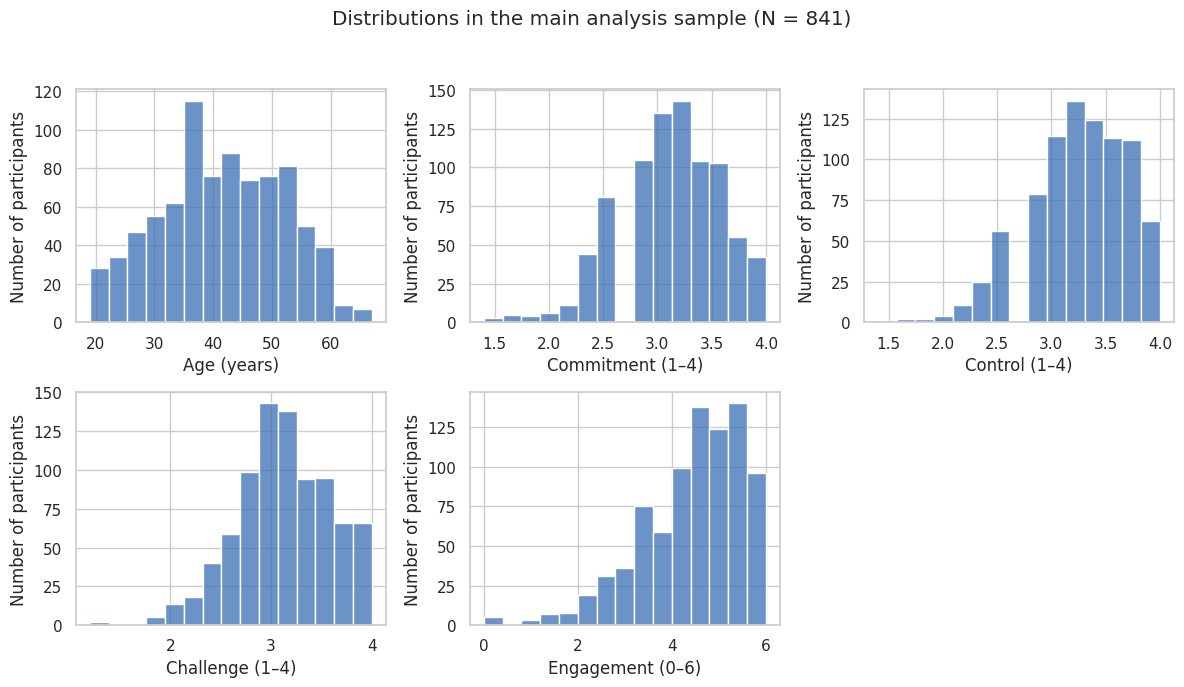

In [8]:
# Inspect the distributions of the main model variables
plot_vars = [
    ("AGE", "Age (years)"),
    ("COMMITMENT", "Commitment (1–4)"),
    ("CONTROL", "Control (1–4)"),
    ("CHALLENGE", "Challenge (1–4)"),
    ("ENGAGEMENT", "Engagement (0–6)")
]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, (variable, label) in zip(axes.ravel(), plot_vars):
    sns.histplot(
        data=df,
        x=variable,
        bins=15,
        color="#3b6fb6",
        edgecolor="white",
        ax=ax
    )
    ax.set_xlabel(label)
    ax.set_ylabel("Number of participants")

# Hide the unused panel
axes.ravel()[-1].axis("off")

fig.suptitle(f"Distributions in the main analysis sample (N = {len(df)})")
fig.tight_layout(rect=[0, 0, 1, 0.95])

fig.savefig(FIG_DIR / "distributions.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation of the distributions

In the main analysis sample, mean engagement is approximately
4.43 on a 0–6 scale. Scores are concentrated towards the upper
part of the scale, with a longer tail towards lower values.

The three hardiness dimensions also have relatively high
average scores, ranging from approximately 3.13 to 3.27
on a 1–4 scale.

These patterns indicate that lower scores are less common
in this sample. However, high average scores alone do not
establish a ceiling effect: this would require examining
the concentration of responses at or near the maximum.

Linear regression does not require the predictors or the
outcome to be normally distributed. We examine the model
residuals separately in the diagnostics section.

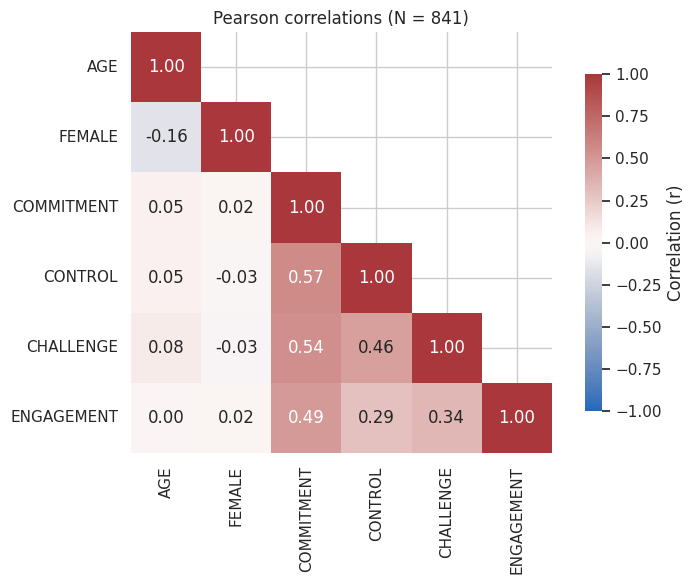

In [9]:
# Pairwise correlations in the main analysis sample
corr_vars = ["AGE", "FEMALE"] + HARD + ["ENGAGEMENT"]
corr = df[corr_vars].corr()

# Hide the upper triangle to avoid showing each correlation twice
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    cbar_kws={"label": "Correlation (r)", "shrink": 0.8},
    ax=ax
)

ax.set_title(f"Pearson correlations (N = {len(df)})")
plt.tight_layout()

fig.savefig(FIG_DIR / "correlations.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation of the correlations

The three hardiness dimensions are positively correlated with
each other (r approximately .46–.57). They capture related,
but not identical, aspects of occupational hardiness.

Control has a positive correlation with engagement
(r approximately .29). However, this is a pairwise association:
it does not account for commitment, challenge, age, or gender.

The multiple regression examines the association of each
hardiness dimension with engagement while holding the other
included predictors constant. These adjusted associations
may differ from the pairwise correlations because the
predictors share information.

Age and gender show small pairwise correlations with engagement
in this sample. They remain in the model as the demographic
covariates specified in the analytical plan.

Neither correlations nor adjusted regression coefficients
establish causal relationships.

## 4. Hierarchical regression: main analysis

### Why use multiple regression?

Multiple linear regression estimates the association between
each predictor and engagement while holding the other included
predictors constant.

We fit two models using the same 841 participants:

- **Model 1:** age and gender.
- **Model 2:** age, gender, commitment, control, and challenge.

Using the same participants ensures that the comparison reflects
the addition of predictors rather than a change in the sample.
Here, “hierarchical” refers to entering predictors in planned
blocks; it does not mean a multilevel model.

### What do we compare?

**R²** describes the proportion of variation in engagement
accounted for by a model in this sample.

The **increase in R²** shows how much additional variation
is accounted for when the three hardiness dimensions are
added to age and gender.

We also use a joint test to assess whether the three hardiness
coefficients are all zero, conditional on age and gender.
A significant result indicates that at least one of these
coefficients differs from zero; it does not establish that
all three do.

### How do we assess uncertainty?

We use **HC3 robust standard errors** to calculate confidence
intervals and p-values for Model 2 and its joint test.
This approach allows for unequal error variance across
observations, a concern examined in the diagnostics section.

HC3 changes the estimated uncertainty, not the regression
coefficients. It does not correct an incorrectly specified
relationship or bias caused by sample selection.

These models describe associations in the available sample.
Their R² values do not measure predictive performance on new data.

In [10]:
# Full model formula, reused in the sensitivity analysis
FORM = "{y} ~ AGE + FEMALE + COMMITMENT + CONTROL + CHALLENGE"

# Fit both models on the same complete-case sample
m1 = smf.ols("ENGAGEMENT ~ AGE + FEMALE", data=df).fit()

m2 = smf.ols(
    FORM.format(y="ENGAGEMENT"), data=df
).fit()

# Full model with HC3 robust standard errors
m2_hc3 = smf.ols(
    FORM.format(y="ENGAGEMENT"), data=df
).fit(cov_type="HC3")

# Compare model fit
model_summary = pd.DataFrame({
    "N": [int(m1.nobs), int(m2.nobs)],
    "R²": [m1.rsquared, m2.rsquared],
    "Adjusted R²": [m1.rsquared_adj, m2.rsquared_adj]
}, index=[
    "Model 1: age and gender",
    "Model 2: age, gender and hardiness"
])

display(model_summary)

delta_r2 = m2.rsquared - m1.rsquared
print(f"Increase in R²: {delta_r2:.3f}")

# Joint test: all three hardiness coefficients are zero
joint_test = m2_hc3.f_test(
    "COMMITMENT = 0, CONTROL = 0, CHALLENGE = 0"
)

print(
    f"HC3 robust joint F-test: "
    f"F({int(joint_test.df_num)}, {int(joint_test.df_denom)}) "
    f"= {float(joint_test.fvalue):.2f}, "
    f"p = {float(joint_test.pvalue):.3g}"
)

,N,R²,Adjusted R²
Model 1: age and gender,841,0.000,-0.002
"Model 2: age, gender and hardiness",841,0.250,0.246


Increase in R²: 0.250
HC3 robust joint F-test: F(3, 835) = 77.42, p = 3.42e-44


### Interpretation of the model comparison

The model including only age and gender accounts for very little
of the variation in engagement in this sample (R² rounds to .000).

Adding commitment, control, and challenge increases R² by
approximately .250. The full model therefore accounts for about
25% of the observed variation in engagement.

Its adjusted R² is .246. This measure takes the number of
predictors and sample size into account.

The HC3 robust joint test provides evidence that the three
hardiness coefficients are not all zero:
F(3, 835) = 77.42, p < .001.

This does not mean that every hardiness dimension has a clear
adjusted association with engagement. The coefficient table
below examines each dimension separately.

The increase in R² describes model fit in this sample.
It does not establish causality or show how well the model
would predict engagement in new participants.

In [11]:
# Format p-values for the results tables
def fmt_p(p):
    return "<.001" if p < .001 else f"{p:.3f}"


# Coefficients and confidence intervals from the HC3 model
ci = m2_hc3.conf_int()

results = pd.DataFrame({
    "b": m2_hc3.params,
    "Robust SE": m2_hc3.bse,
    "95% CI lower": ci[0],
    "95% CI upper": ci[1],
    "p": m2_hc3.pvalues.map(fmt_p)
})

# Standardized coefficients for continuous predictors
continuous_predictors = ["AGE"] + HARD
results["Beta"] = np.nan

for predictor in continuous_predictors:
    results.loc[predictor, "Beta"] = (
        m2_hc3.params[predictor]
        * df[predictor].std()
        / df["ENGAGEMENT"].std()
    )

# Arrange columns for readability
results = results[
    ["b", "Beta", "Robust SE", "95% CI lower", "95% CI upper", "p"]
]

display(results.round(3))

,b,Beta,Robust SE,95% CI lower,95% CI upper,p
Intercept,0.687,NaN,0.341,0.019,1.355,0.044
AGE,-0.003,-0.024,0.003,-0.009,0.003,0.404
FEMALE,0.027,NaN,0.069,-0.107,0.162,0.692
COMMITMENT,1.008,0.438,0.092,0.829,1.188,<.001
CONTROL,-0.022,-0.009,0.095,-0.207,0.164,0.819
CHALLENGE,0.237,0.109,0.082,0.076,0.399,0.004


### How to read the coefficient table

**b** is the estimated difference in engagement associated with
a one-point increase in a predictor, holding the other predictors
constant. For FEMALE, it represents the adjusted difference
between women (1) and men (0).

**Beta** expresses the association in standard deviation units
for continuous predictors. The 95% confidence intervals refer
to the unstandardized coefficients b and use HC3 robust
standard errors.

### Main findings

**Commitment** has the largest standardized association among
the three hardiness dimensions (Beta = .438).
A one-point higher commitment score is associated with
approximately 1.01 points higher engagement, holding the other
predictors constant (b = 1.008, 95% CI [0.829, 1.188], p < .001).

**Challenge** shows a smaller positive adjusted association
(Beta = .109; b = 0.237, 95% CI [0.076, 0.399], p = .004).

**Control** shows no clear adjusted association in the main
sample (b = -0.022, 95% CI [-0.207, 0.164], p = .819).
Its positive pairwise correlation with engagement does not
translate into a clear association after accounting for
the other predictors.

**Age and gender** also have confidence intervals that include
zero. This does not establish that their associations are
exactly zero.

### Interpretation boundaries

These estimates describe differences between participants,
not changes caused by increasing hardiness. The association
for commitment may partly reflect its conceptual overlap
with engagement.

The sensitivity analysis examines whether the findings
remain similar when the outcome definition and sample change.

## 5. Model diagnostics

Diagnostics help identify patterns that may limit the interpretation
of a regression model.

A residual is the difference between a participant's observed
engagement score and the score estimated by the model.

We examine:

- **Residuals versus fitted values:** a curved pattern may suggest
  that the model does not adequately describe the relationship.
- **Q–Q plot:** departures from the reference line indicate
  departures from a normal residual distribution.
- **Scale-location plot:** changes in residual spread suggest
  unequal error variance, also called heteroskedasticity.
- **Cook's distance:** identifies observations that may have
  a relatively large influence on the estimated coefficients.
- **Variance inflation factors (VIF):** assess how strongly
  relationships among predictors inflate coefficient uncertainty.

We also use the Breusch–Pagan and Shapiro–Wilk tests as supporting
checks for unequal error variance and departures from normality.
We interpret them alongside the plots, rather than as simple
pass-or-fail rules.

The analysis assumes independent observations. These plots cannot
establish independence; this depends on how participants were
recruited and how the data were collected.

HC3 robust standard errors allow for unequal error variance.
They do not correct nonlinearity, dependence between observations,
or sample selection bias.

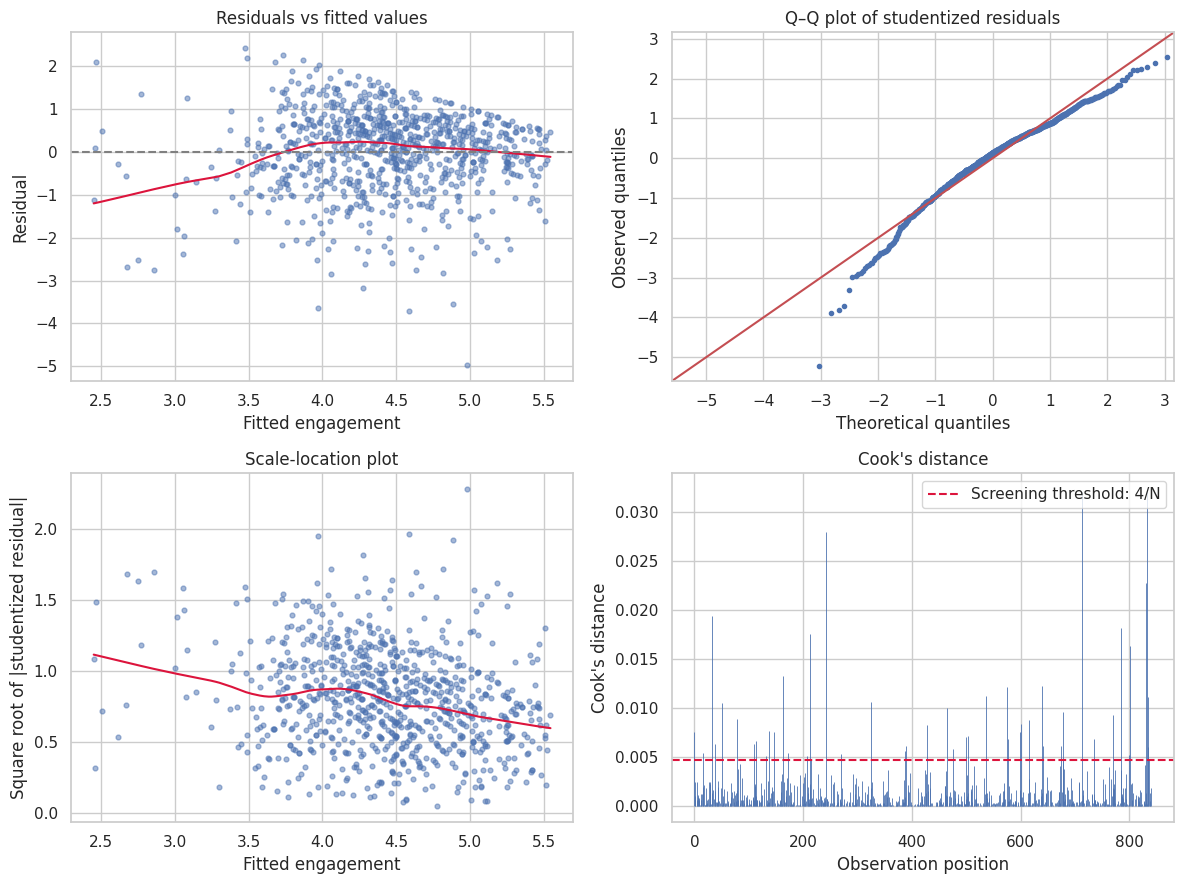

In [12]:
# Calculate residuals and influence measures
infl = m2.get_influence()
stud = infl.resid_studentized_internal
cooks = infl.cooks_distance[0]
fitted = m2.fittedvalues

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# 1. Residuals versus fitted values
ax = axes[0, 0]
ax.scatter(fitted, m2.resid, s=12, alpha=0.5)
smooth = lowess(m2.resid, fitted, frac=0.4)
ax.plot(smooth[:, 0], smooth[:, 1], color="crimson")
ax.axhline(0, linestyle="--", color="grey")
ax.set(
    title="Residuals vs fitted values",
    xlabel="Fitted engagement",
    ylabel="Residual"
)

# 2. Residual distribution compared with a normal distribution
sm.qqplot(stud, line="45", ax=axes[0, 1], markersize=3)
axes[0, 1].set(
    title="Q–Q plot of studentized residuals",
    xlabel="Theoretical quantiles",
    ylabel="Observed quantiles"
)

# 3. Residual spread across fitted values
ax = axes[1, 0]
spread = np.sqrt(np.abs(stud))
ax.scatter(fitted, spread, s=12, alpha=0.5)
smooth = lowess(spread, fitted, frac=0.4)
ax.plot(smooth[:, 0], smooth[:, 1], color="crimson")
ax.set(
    title="Scale-location plot",
    xlabel="Fitted engagement",
    ylabel="Square root of |studentized residual|"
)

# 4. Influence of individual observations
ax = axes[1, 1]
ax.vlines(np.arange(len(cooks)), 0, cooks, linewidth=0.6)
ax.axhline(
    4 / len(df),
    linestyle="--",
    color="crimson",
    label="Screening threshold: 4/N"
)
ax.set(
    title="Cook's distance",
    xlabel="Observation position",
    ylabel="Cook's distance"
)
ax.legend()

plt.tight_layout()
fig.savefig(FIG_DIR / "diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
# Tests supporting the visual diagnostics
bp_stat, bp_p, _, _ = het_breuschpagan(
    m2.resid, m2.model.exog
)
shapiro_stat, shapiro_p = stats.shapiro(m2.resid)

tests = pd.DataFrame({
    "Test": ["Breusch–Pagan", "Shapiro–Wilk"],
    "What it checks": [
        "Equal error variance",
        "Normality of residuals"
    ],
    "p": [fmt_p(bp_p), fmt_p(shapiro_p)]
})

display(tests)

# Summarise potentially influential observations
print(f"Maximum Cook's distance: {cooks.max():.3f}")
print(
    "Observations above the 4/N screening threshold: "
    f"{int((cooks > 4 / len(df)).sum())}"
)
print(
    "Observations with |studentized residual| > 3: "
    f"{int((np.abs(stud) > 3).sum())}"
)

# Check collinearity among predictors
vif = pd.DataFrame({
    "Predictor": m2.model.exog_names[1:],
    "VIF": [
        variance_inflation_factor(m2.model.exog, i)
        for i in range(1, m2.model.exog.shape[1])
    ]
})

display(vif.round(2))

,Test,What it checks,p
0,Breusch–Pagan,Equal error variance,0.003
1,Shapiro–Wilk,Normality of residuals,<.001


Maximum Cook's distance: 0.032
Observations above the 4/N screening threshold: 46
Observations with |studentized residual| > 3: 5


,Predictor,VIF
0,AGE,1.030
1,FEMALE,1.030
2,COMMITMENT,1.750
3,CONTROL,1.560
4,CHALLENGE,1.500


### Diagnostic results

**Collinearity.** VIF values are all below 1.75. This suggests
that collinearity is not a major source of uncertainty in
the estimated coefficients, despite the correlations among
the hardiness dimensions.

**Unequal error variance.** The Breusch–Pagan test provides
evidence against constant error variance (p approximately .003).
This supports using HC3 robust standard errors for confidence
intervals and significance tests.

**Residual distribution.** The Shapiro–Wilk test indicates
departures from normality (p < .001). There are five observations
with absolute studentized residuals greater than 3.
These findings do not automatically invalidate the regression,
but indicate that some observations are poorly described
by the model. HC3 does not make the residuals normally distributed.

**Influential observations.** The maximum Cook's distance is .032,
and 46 observations exceed the 4/N screening threshold.
Crossing this threshold is a reason for closer examination,
not an automatic reason for exclusion. All observations
are retained; sensitivity to removing flagged cases has
not been assessed.

**Linearity.** The residual plot shows some curvature at low
fitted values, where observations are sparse. The linear model
may therefore describe this part of the sample less adequately.

### Implications for interpretation

We report the regression as a summary of adjusted linear
associations, with HC3 robust confidence intervals.
The diagnostic concerns remain limitations: robust standard
errors address unequal error variance, but do not correct
the form of the relationship or possible selection bias.

In [14]:
def ci_str(lo, hi):
    return f"[{lo:.3f}, {hi:.3f}]"

## 6. Sensitivity analysis: missing data and sample selection

### Why is this check needed?

There are 1,129 participants with complete data on age, gender,
the three hardiness dimensions, vigor, and dedication.
Of these, 288 have missing absorption scores.

The main analysis therefore includes 841 participants.
If those excluded differ from those included, the associations
estimated in the main sample may not reflect those in the
larger sample.

We address this concern in two steps:

1. Compare observed characteristics of participants with
   and without absorption scores.
2. Compare regression results across three analyses that
   vary the outcome definition or the sample.

These checks explore sensitivity to analytical choices.
They do not recover missing absorption scores or establish
that selection bias has been removed.

### 6.1 Who has missing absorption scores?

We compare age, hardiness, vigor, dedication, and the percentage
of women between the two groups.

Differences in observed characteristics can provide evidence
against missingness being completely random. However, they
cannot determine whether missingness also depends on the
unobserved absorption scores themselves.

In [15]:
# Identify participants with and without absorption scores
base["ABS_MISSING"] = base["ABSORPTION"].isna()

observed = base.loc[~base["ABS_MISSING"]]
missing_abs = base.loc[base["ABS_MISSING"]]

print(f"Absorption observed: N = {len(observed)}")
print(f"Absorption missing: N = {len(missing_abs)}")

# Compare group means
compare_vars = [
    "AGE", "COMMITMENT", "CONTROL",
    "CHALLENGE", "VIGOR", "DEDICATION"
]

comparison = pd.DataFrame({
    "Mean: absorption observed": observed[compare_vars].mean(),
    "Mean: absorption missing": missing_abs[compare_vars].mean()
})

comparison["Difference: missing minus observed"] = (
    comparison["Mean: absorption missing"]
    - comparison["Mean: absorption observed"]
)

display(comparison.round(2))

# Compare gender composition
print(f"\nWomen, absorption observed: {observed['FEMALE'].mean():.1%}")
print(f"Women, absorption missing: {missing_abs['FEMALE'].mean():.1%}")

Absorption observed: N = 841
Absorption missing: N = 288


,Mean: absorption observed,Mean: absorption missing,Difference: missing minus observed
AGE,41.510,47.340,5.830
COMMITMENT,3.130,3.290,0.160
CONTROL,3.270,3.310,0.040
CHALLENGE,3.160,3.200,0.040
VIGOR,4.200,4.540,0.340
DEDICATION,4.530,5.010,0.490



Women, absorption observed: 58.7%
Women, absorption missing: 44.1%


### Interpretation of the group comparison

Participants with missing absorption scores are, on average,
older than those with observed scores (47.34 versus 41.51 years).
The percentage of women is also lower (44.1% versus 58.7%).

The group with missing absorption has higher average commitment,
vigor, and dedication scores. Average control and challenge
scores differ less between the groups.

These descriptive differences suggest that excluding participants
with missing absorption changes the composition of the sample.
They raise concerns about treating the excluded participants
as interchangeable with those retained, but do not establish
why absorption scores are missing.

### 6.2 Do the conclusions change? Three analyses compared

We fit the same regression formula in three settings:

| Analysis | Outcome | Participants |
|---|---|---|
| A: Main analysis | Mean of vigor, dedication, and absorption | 841 |
| B: Alternative outcome | Mean of vigor and dedication | The same 841 |
| C: Larger sample | Mean of vigor and dedication | 1,129 |

All three models include age, gender, commitment, control,
and challenge, and use HC3 robust standard errors.

**Comparing A and B** changes the outcome definition while
keeping the participants fixed.

**Comparing B and C** changes the sample while keeping the
outcome definition fixed.

The two-subscale outcome does not capture absorption and is
not equivalent to the full engagement score. It allows us
to include more participants without imputing missing values.

These comparisons assess sensitivity to the outcome definition
and sample selection. They cannot tell us what the results
would have been if absorption had been observed for everyone.

In [16]:
# Alternative outcome: mean of vigor and dedication
df["ENG_VD"] = df[["VIGOR", "DEDICATION"]].mean(axis=1)

# A: main outcome, complete-case sample
model_a = smf.ols(
    FORM.format(y="ENGAGEMENT"), data=df
).fit(cov_type="HC3")

# B: alternative outcome, same sample
model_b = smf.ols(
    FORM.format(y="ENG_VD"), data=df
).fit(cov_type="HC3")

# C: alternative outcome, larger sample
model_c = smf.ols(
    FORM.format(y="ENG_VD"), data=base
).fit(cov_type="HC3")

models = {
    "A: Three subscales, N=841": model_a,
    "B: Vigor + dedication, N=841": model_b,
    "C: Vigor + dedication, N=1129": model_c,
}

rows = []

for label, model in models.items():
    ci = model.conf_int()

    for predictor in HARD:
        rows.append({
            "Analysis": label,
            "Predictor": predictor,
            "b": model.params[predictor],
            "95% CI": ci_str(
                ci.loc[predictor, 0],
                ci.loc[predictor, 1]
            ),
            "p": fmt_p(model.pvalues[predictor]),
        })

sensitivity_table = pd.DataFrame(rows)
display(sensitivity_table)

,Analysis,Predictor,b,95% CI,p
0,"A: Three subscales, N=841",COMMITMENT,1.008,"[0.829, 1.188]",<.001
1,"A: Three subscales, N=841",CONTROL,-0.022,"[-0.207, 0.164]",0.819
2,"A: Three subscales, N=841",CHALLENGE,0.237,"[0.076, 0.399]",0.004
3,"B: Vigor + dedication, N=841",COMMITMENT,1.130,"[0.925, 1.335]",<.001
4,"B: Vigor + dedication, N=841",CONTROL,-0.101,"[-0.311, 0.109]",0.347
5,"B: Vigor + dedication, N=841",CHALLENGE,0.227,"[0.045, 0.409]",0.015
6,"C: Vigor + dedication, N=1129",COMMITMENT,0.900,"[0.725, 1.074]",<.001
7,"C: Vigor + dedication, N=1129",CONTROL,0.189,"[0.005, 0.373]",0.045
8,"C: Vigor + dedication, N=1129",CHALLENGE,0.230,"[0.071, 0.390]",0.005


### Interpretation of the sensitivity analysis

**Commitment** has a positive adjusted association with the
outcome in all three analyses. Its coefficients are 1.008
in A, 1.130 in B, and 0.900 in C, with all confidence
intervals excluding zero. The direction is consistent,
although the estimated magnitude varies.

**Challenge** also has a positive adjusted association in
all three analyses. Its coefficients are similar:
0.237 in A, 0.227 in B, and 0.230 in C.
All three confidence intervals exclude zero.

**Control** is more sensitive to the analytical choices.
Its coefficients are close to zero or slightly negative
in A and B, with confidence intervals including zero.
In the larger sample (C), the coefficient is positive
(b = 0.189, 95% CI [0.005, 0.373], p = .045).
This interval only narrowly excludes zero, so the evidence
should be interpreted cautiously.

### What does the comparison tell us?

Comparing A and B suggests that removing absorption from
the outcome does not change the overall pattern of findings
among the same 841 participants.

Comparing B and C shows that the control estimate changes
when additional participants are included, even though the
outcome definition remains the same. This indicates that
the finding for control is sensitive to sample selection.

However, a coefficient being statistically significant in
one analysis and not in another does not itself demonstrate
a statistically significant difference between the coefficients.

Overall, the positive associations for commitment and challenge
are consistent across the three analyses examined.
The conclusion for control is less stable.

These analyses use overlapping participants and are not
independent replications. They also do not eliminate
possible bias from missing data.




## 7. Discussion and conclusions

### Answer to the research question

In the main sample of 841 Italian workers, commitment and
challenge are positively associated with work engagement
after accounting for age, gender, and the other hardiness
dimensions.

Commitment has the largest standardized association among
the three dimensions. Control shows no clear adjusted
association in the main analysis.

The full model accounts for approximately 25% of the observed
variation in engagement (adjusted R² = .246). This describes
model fit in the analysis sample, not predictive performance
on new participants.

### Assessment of the hypotheses

| Hypothesis | Assessment |
|---|---|
| H1: Higher commitment is associated with higher engagement. | Supported in the main analysis. The association remains positive in both sensitivity analyses, although its magnitude varies. |
| H2: Higher control is associated with higher engagement. | Not supported in the main analysis. A positive association emerges with the alternative outcome in the larger sample, so the conclusion is sensitive to sample selection. |
| H3: Higher challenge is associated with higher engagement. | Supported in the main analysis, with a smaller association than commitment. The positive association is similar across the sensitivity analyses. |

### Interpretation

The findings are consistent with the idea that involvement
in work and openness to challenges are related to engagement.
However, commitment and engagement share aspects of involvement
and meaning, which may partly explain their association.

The results do not show that increasing hardiness would improve
engagement. Engagement could influence how people describe
their hardiness, or both could reflect other personal and
workplace characteristics.

The result for control illustrates why analytical choices matter:
the conclusion changes when the sample is expanded.
It would therefore be misleading to conclude simply that
control is unrelated to engagement.

### Main limitations

- **Cross-sectional, self-report data:** the analysis cannot
  establish causality, and shared response tendencies may
  contribute to the associations.

- **Missing data and sample selection:** missing absorption
  scores exclude many participants from the main analysis.
  The sensitivity checks explore this issue but do not
  remove possible selection bias.

- **Limited adjustment:** age and gender do not capture all
  relevant characteristics. Job conditions and other unmeasured
  factors may influence the observed relationships.

- **Measurement:** only subscale scores are available, so
  item-level scoring and reliability cannot be checked.
  The two-subscale outcome used in the sensitivity analysis
  is not equivalent to the full engagement score.

- **Model limitations:** diagnostics indicate unequal error
  variance, non-normal residuals, and some curvature at low
  fitted values. HC3 addresses unequal error variance in
  statistical inference, but does not correct the model's
  functional form. Sensitivity to influential observations
  has not been assessed.

- **Generalizability:** the findings cannot automatically be
  extended to all Italian workers. The sensitivity analyses
  use overlapping data and are not independent replications.

### Future directions

Useful next steps would be to clarify why absorption scores
are missing and repeat the analysis in an independent sample.
Longitudinal data and information on workplace conditions
would help investigate the direction and context of the
observed associations.

### Conclusion

Commitment and challenge show consistent positive adjusted
associations across the analyses examined, while the result
for control is sensitive to the sample used.

The project demonstrates the importance of examining data
quality, interpreting coefficients alongside their uncertainty,
and checking how analytical choices affect conclusions.

## 8. Reproducibility and references

### How to run this notebook in Google Colab

1. Download `Occupational_hardiness_ITA.sav` from the OSF
   repository linked in the Data source section.
2. In your Google Drive, create a folder named
   `Hardiness_Project` directly inside My Drive.
3. Upload the dataset into that folder, keeping its filename
   unchanged.
4. Open this notebook in Google Colab and run all cells
   from top to bottom.
5. When prompted, authorise Colab to connect to your Google Drive.

The notebook reads the dataset from:
`/content/drive/MyDrive/Hardiness_Project/Occupational_hardiness_ITA.sav`

Other users can reproduce the analysis by creating the same
folder structure in their own Google Drive.

### Data and output storage

The dataset remains in Google Drive when a Colab session ends.
Exported figures are saved in the `figures` subfolder within
`Hardiness_Project`.

After starting a new session, rerun the notebook and reconnect
Google Drive if prompted. There is no need to upload the dataset
again.

The main analysis should include 841 participants, and the
larger sensitivity sample should include 1,129.

### Software versions

The analysis uses Python, NumPy, pandas, Matplotlib, seaborn,
SciPy, statsmodels, and pyreadstat. The first cell installs
pyreadstat; the other packages are available in the Colab
environment used for this project.

The following cell records the Python and library versions
used to run the analysis.

In [17]:
from importlib.metadata import version

print(f"Python: {platform.python_version()}")

packages = [
    "numpy",
    "pandas",
    "matplotlib",
    "seaborn",
    "scipy",
    "statsmodels",
    "pyreadstat"
]

for package in packages:
    print(f"{package}: {version(package)}")

Python: 3.13.16
numpy: 2.1.3
pandas: 2.2.3
matplotlib: 3.10.0
seaborn: 0.13.2
scipy: 1.16.3
statsmodels: 0.15.0
pyreadstat: 1.3.6


### References

- Bakker, A. B., & Demerouti, E. (2007). The Job Demands–Resources
  model: State of the art. *Journal of Managerial Psychology,
  22*(3), 309–328.

- Kobasa, S. C. (1979). Stressful life events, personality, and
  health: An inquiry into hardiness. *Journal of Personality
  and Social Psychology, 37*(1), 1–11.

- Long, J. S., & Ervin, L. H. (2000). Using heteroscedasticity
  consistent standard error estimators in OLS regression.
  *The American Statistician, 54*(3), 217–224.

- Panari, C., Mazzetti, G., Lo Piccolo, E., Guglielmi, D.,
  & Simbula, S. (2026). A contribution to the Italian validation
  of the occupational hardiness scale and its role in work
  engagement and emotional exhaustion.
  *Scientific Reports, 16*, 924.
  https://doi.org/10.1038/s41598-025-29016-z

- Schaufeli, W. B., Salanova, M., González-Romá, V., & Bakker,
  A. B. (2002). The measurement of engagement and burnout:
  A two sample confirmatory factor analytic approach.
  *Journal of Happiness Studies, 3*(1), 71–92.